# Pause, step by step

For people who hand errands to an AI assistant, it removes the fear that the agent will confidently do the wrong thing.

This notebook follows the course order: model, system prompt, tools, memory, images and audio. Then it shows the part that is specific to Pause: the uncertainty gate. Everything runs against a simulated workspace in a temporary SQLite file.

In [1]:
import logging, os, tempfile, warnings
warnings.filterwarnings('ignore')
logging.getLogger('google_genai').setLevel(logging.ERROR)
os.chdir(os.path.abspath('..'))
from dotenv import load_dotenv
load_dotenv()
from pause.config import settings
from pause.tools import PauseContext

NOW = '2026-10-06T09:00:00'  # a Tuesday, fixed so the outputs repeat
def fresh_context():
    return PauseContext(NOW, 'Europe/London', os.path.join(tempfile.mkdtemp(), 'ws.sqlite'))
settings.model

'google_genai:gemini-3.1-flash-lite'

## 1. The model and `create_agent`

One factory, `make_model`, wraps `init_chat_model`. The smallest agent is a model with no tools.

In [2]:
from langchain.agents import create_agent
from pause.models import make_model

model = make_model()
plain = create_agent(model, tools=[])
plain.invoke({'messages': [{'role': 'user', 'content': 'Say hello in five words.'}]})['messages'][-1].text

'Hello, it is nice meeting.'

## 2. The system prompt

The prompt sets the role, the rules for dates, people and ids, how to treat tool output, and the limits. A small middleware adds the run's clock to it, so the model never has to guess what today is.

In [3]:
from pause.prompts import BASE_PROMPT
from pause.agent import clock_line
print(BASE_PROMPT + clock_line(fresh_context()))

You are Pause, a personal assistant for one user's workspace: a calendar, a task list, contacts and notes. It is a simulated workspace. Nothing is sent to real people.

# What you do
- Read and change the calendar, tasks and notes with your tools.
- Turn a photo of a flyer, whiteboard or handwritten list, or a voice note, into events or tasks.
- Look up public facts on the web when a request needs one, such as a holiday date.
You do not give advice, write documents, or act outside this workspace.

# How to work
1. Dates: always call resolve_date with the user's phrase. Never compute a date yourself.
2. People: always call find_contact and use the contact id. Never guess an id.
3. Events and tasks: call list_events or list_tasks to get ids. Never invent an id.
4. Make only the change the user asked for. One request, one change, unless they listed several.
5. If something the user asks for cannot be done, for example the event does not exist, say so plainly and change nothing.

# Tool ou

## 3. Tools

A deterministic tool first. `resolve_date` is plain Python and says when a phrase has more than one honest reading. Then the agent uses its tools on the seeded workspace, where two people are called Sam.

In [4]:
from pause.dates import resolve_date
for phrase in ['tomorrow at 3pm', 'next Friday', 'Friday the 10th', 'tomorrow at 3']:
    r = resolve_date(phrase, 'Europe/London', NOW)
    print(f'{phrase!r:22} -> {r.iso or r.alternatives}  {r.note}')

'tomorrow at 3pm'      -> 2026-10-07T15:00:00+01:00  
'next Friday'          -> ['2026-10-09', '2026-10-16']  'next' can mean this week's or the week after
'Friday the 10th'      -> ['2026-10-09', '2026-10-10']  the next 10th is not a Friday
'tomorrow at 3'        -> ['2026-10-07T03:00:00+01:00', '2026-10-07T15:00:00+01:00']  'at 3' has no am or pm


In [5]:
from pause.agent import build_agent

def show(result):
    for m in result['messages']:
        if m.type == 'ai' and m.tool_calls:
            for c in m.tool_calls: print('->', c['name'], c['args'])
    print('pause:', result['messages'][-1].text)

agent = build_agent(setup='no_gate')
show(agent.invoke({'messages': [{'role': 'user', 'content': 'What is on my calendar on Friday?'}]}, context=fresh_context()))

-> resolve_date {'expression': 'Friday'}
-> list_events {'start': '2026-10-09', 'end': '2026-10-10'}
pause: On Friday, October 9, you have "Budget sync" from 09:30 to 10:00 and "Team lunch" in the Canteen from 12:30 to 13:30.


## 4. Short-term memory

A checkpointer keeps each thread by `thread_id`, so a short reply makes sense. Deleting is the one action that cannot be undone, so it stops for approval.

In [6]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

ctx = fresh_context()
agent = build_agent(checkpointer=InMemorySaver(), setup='gate')
thread = {'configurable': {'thread_id': 'notebook'}}
first = agent.invoke({'messages': [{'role': 'user', 'content': 'Delete the design review.'}]}, thread, context=ctx)
first['messages'][-1].text

'The design review on Thursday, 8 October 2026, from 2:00 PM to 3:00 PM will be deleted. Do you confirm?'

In [7]:
second = agent.invoke({'messages': [{'role': 'user', 'content': 'The Thursday one.'}]}, thread, context=ctx)
print('gate:', [(g['decision'], g['agreement'], g['options']) for g in second['gate_log']])
print('waiting for approval:', [a['name'] for a in second['__interrupt__'][0].value['action_requests']])

gate: [('act', 1.0, ["delete 'Design review' on Thu 8 Oct 14:00"])]
waiting for approval: ['delete_event']


In [8]:
from pause.tools import workspace_of
done = agent.invoke(Command(resume={'decisions': [{'type': 'approve'}]}), thread, context=ctx)
print(done['messages'][-1].text)
[(e['title'], e['start']) for e in workspace_of(ctx).events()]

I've deleted the design review on Thursday, 8 October 2026.


[('Design review', '2026-10-05T10:00'),
 ('1:1 with Priya', '2026-10-06T11:00'),
 ('Dentist', '2026-10-07T16:00'),
 ('Budget sync', '2026-10-09T09:30'),
 ('Team lunch', '2026-10-09T12:30')]

## 5. Images and audio

A flyer photo becomes an event and a voice note becomes a task. Both go to Gemini as standard content blocks. The audio is sent as audio, with no separate transcription step.

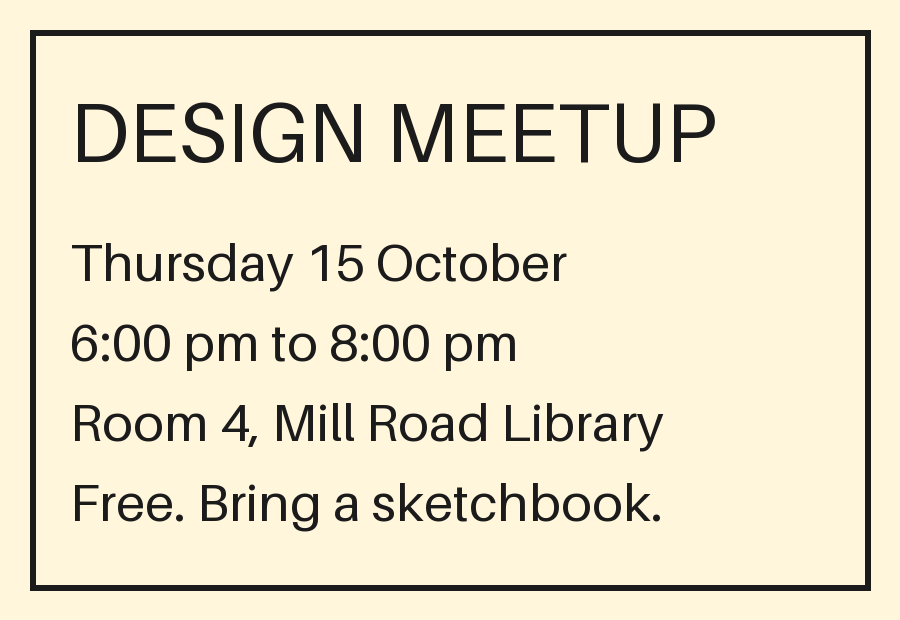

-> resolve_date {'expression': 'Thursday 15 October 2026 6:00 pm'}
-> resolve_date {'expression': 'Thursday 15 October 2026 8:00 pm'}
-> create_event {'end': '2026-10-15T20:00:00+01:00', 'start': '2026-10-15T18:00:00+01:00', 'location': 'Room 4, Mill Road Library', 'title': 'Design Meetup', 'attendee_ids': []}
pause: I've added the "Design Meetup" to your calendar for Thursday, 15 October 2026, from 6:00 pm to 8:00 pm.


In [9]:
from pathlib import Path
from IPython.display import Image, display
from pause.media import audio_block, clean_image, image_block

display(Image('samples/flyer.png', width=360))
ctx = fresh_context()
png = clean_image(Path('samples/flyer.png').read_bytes(), 'image/png')
agent = build_agent(setup='gate')
show(agent.invoke({'messages': [{'role': 'user', 'content': [{'type': 'text', 'text': 'Add this to my calendar.'}, image_block(png)]}]}, context=ctx))

In [10]:
wav = Path('samples/voice_note.wav').read_bytes()  # says: add a task to renew my passport, due next Monday
show(agent.invoke({'messages': [{'role': 'user', 'content': [audio_block(wav, 'audio/wav')]}]}, context=ctx))
[(t['title'], t['due']) for t in workspace_of(ctx).tasks()][-1]

-> resolve_date {'expression': 'next Monday'}
-> add_task {'title': 'Renew passport', 'due': '2026-10-12'}
pause: I've added a task to renew your passport, due next Monday, October 12, 2026.


('Renew passport', '2026-10-12')

## 6. The uncertainty gate

When the model proposes a tool call that changes something, the gate asks for two more proposals for the same turn, puts their arguments into one canonical form, and counts how many agree. High agreement runs the action. Lower agreement turns into one question. No majority on something irreversible goes to the user with every option listed.

The decision itself is pure Python, so it can be shown without a model.

In [11]:
from langchain_uncertainty_gate import build_proposal, decide
from pause import gate
from pause.tools import RISK

risk_of = lambda name: RISK.get(name, 'none')
def proposals(*starts):
    return [build_proposal([{'name': 'move_event', 'args': {'event_id': 'e3', 'new_start': s}}], risk_of, gate.canonicalize) for s in starts]

for starts in [('2026-10-09T15:00',) * 3, ('2026-10-09T15:00', '2026-10-16T15:00', '2026-10-09T15:00'), ('2026-10-09T15:00', '2026-10-16T15:00', '2026-10-10T15:00')]:
    d = decide(proposals(*starts), risk_of)
    print(d.decision, d.agreement, d.votes)

act 1.0 [3]
act 0.667 [2, 1]
ask 0.333 [1, 1, 1]


In [12]:
ctx = fresh_context()
agent = build_agent(setup='gate')
result = agent.invoke({'messages': [{'role': 'user', 'content': 'Move my dentist appointment to next Friday at 3pm.'}]}, context=ctx)
show(result)
[(g['decision'], g['agreement'], g['votes'], g['options']) for g in result.get('gate_log', [])]

-> list_events {}
-> resolve_date {'expression': 'next Friday at 3pm'}
pause: Could you please clarify whether you mean this Friday, October 9th, or next Friday, October 16th?


[]

The live result above depends on what the model proposes on the day. The eval in `evals/` runs the same requests many times with and without the gate and reports how often each setup takes a wrong action.